# Workshop 3 — Fase A: Análisis Exploratorio de Datos (EDA) y Armonización de Esquemas

**Objetivo:**  
1. Realizar el perfilado y diagnóstico de calidad de los archivos históricos del *World Happiness Report* (`2015.csv` – `2019.csv`).  
2. Identificar inconsistencias de nombres de columnas, tipos de datos, diferencias estructurales entre años, valores faltantes, duplicados y posibles valores atípicos.  
3. Diseñar y ejecutar un pipeline batch de limpieza y armonización que genere un esquema analítico unificado (`data/processed/happiness_unified.csv`) compatible tanto con el entrenamiento ML como con el *Event Contract* de Apache Kafka.

In [1]:
from pathlib import Path
from IPython.display import display
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 140)


def resolve_project_root() -> Path:
    """Resuelve la raíz del proyecto sin importar si Jupyter inicia en /notebooks o en la raíz."""
    cwd = Path.cwd().resolve()
    for candidate in (cwd, cwd.parent):
        if (candidate / "data" / "raw").exists():
            return candidate
    raise FileNotFoundError(
        "No se encontró la carpeta 'data/raw'. Asegúrate de ejecutar este notebook dentro de workshop_3."
    )


PROJECT_ROOT = resolve_project_root()
RAW_DIR = PROJECT_ROOT / "data" / "raw"
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)

YEARS = [2015, 2016, 2017, 2018, 2019]
print(f"Proyecto ubicado en: {PROJECT_ROOT}")
print(f"Archivos CSV encontrados: {[p.name for p in sorted(RAW_DIR.glob('*.csv'))]}")

Proyecto ubicado en: C:\Users\jagui\Desktop\UNIVERSIDAD\ETL\workshop_3
Archivos CSV encontrados: ['2015.csv', '2016.csv', '2017.csv', '2018.csv', '2019.csv']


## Paso 1 — Análisis Exploratorio de Datos (EDA) y Perfilado por Año

Inspeccionamos cada CSV de forma individual para detectar variaciones de esquema, tipos de datos, registros duplicados y valores nulos antes de intentar concatenarlos.

In [2]:
raw_datasets: dict[int, pd.DataFrame] = {}
profiling_summary = []

for year in YEARS:
    file_path = RAW_DIR / f"{year}.csv"
    df_year = pd.read_csv(file_path)
    raw_datasets[year] = df_year

    profiling_summary.append({
        "year": year,
        "rows": df_year.shape[0],
        "columns": df_year.shape[1],
        "exact_duplicates": int(df_year.duplicated().sum()),
        "total_nulls": int(df_year.isna().sum().sum()),
        "column_list": list(df_year.columns),
    })

    print(f"=== {year}.csv | shape={df_year.shape} | nulos={df_year.isna().sum().sum()} ===")
    display(pd.DataFrame({
        "dtype": df_year.dtypes.astype(str),
        "null_count": df_year.isna().sum(),
        "sample_value": df_year.iloc[0],
    }))

summary_df = pd.DataFrame(profiling_summary).drop(columns=["column_list"])
print("\nResumen general por archivo:")
display(summary_df)

=== 2015.csv | shape=(158, 12) | nulos=0 ===


,dtype,null_count,sample_value
Country,str,0,Switzerland
Region,str,0,Western Europe
Happiness Rank,int64,0,1
Happiness Score,float64,0,7.587
Standard Error,float64,0,0.03411
Economy (GDP per Capita),float64,0,1.39651
Family,float64,0,1.34951
Health (Life Expectancy),float64,0,0.94143
Freedom,float64,0,0.66557
Trust (Government Corruption),float64,0,0.41978


=== 2016.csv | shape=(157, 13) | nulos=0 ===


,dtype,null_count,sample_value
Country,str,0,Denmark
Region,str,0,Western Europe
Happiness Rank,int64,0,1
Happiness Score,float64,0,7.526
Lower Confidence Interval,float64,0,7.46
Upper Confidence Interval,float64,0,7.592
Economy (GDP per Capita),float64,0,1.44178
Family,float64,0,1.16374
Health (Life Expectancy),float64,0,0.79504
Freedom,float64,0,0.57941


=== 2017.csv | shape=(155, 12) | nulos=0 ===


,dtype,null_count,sample_value
Country,str,0,Norway
Happiness.Rank,int64,0,1
Happiness.Score,float64,0,7.537
Whisker.high,float64,0,7.594445
Whisker.low,float64,0,7.479556
Economy..GDP.per.Capita.,float64,0,1.616463
Family,float64,0,1.533524
Health..Life.Expectancy.,float64,0,0.796667
Freedom,float64,0,0.635423
Generosity,float64,0,0.362012


... (2 outputs left out)

=== 2019.csv | shape=(156, 9) | nulos=0 ===


,dtype,null_count,sample_value
Overall rank,int64,0,1
Country or region,str,0,Finland
Score,float64,0,7.769
GDP per capita,float64,0,1.34
Social support,float64,0,1.587
Healthy life expectancy,float64,0,0.986
Freedom to make life choices,float64,0,0.596
Generosity,float64,0,0.153
Perceptions of corruption,float64,0,0.393



Resumen general por archivo:


,year,rows,columns,exact_duplicates,total_nulls
0,2015,158,12,0,0
1,2016,157,13,0,0
2,2017,155,12,0,0
3,2018,156,9,0,1
4,2019,156,9,0,0


In [3]:
# Matriz de comparación de esquemas para evidenciar la deriva estructural (schema drift) entre 2015 y 2019
all_raw_columns = sorted({col for df in raw_datasets.values() for col in df.columns})
schema_matrix = pd.DataFrame(
    {year: [col in raw_datasets[year].columns for col in all_raw_columns] for year in YEARS},
    index=all_raw_columns,
)
schema_matrix["years_present"] = schema_matrix.sum(axis=1)
schema_matrix = schema_matrix.sort_values(by=["years_present"], ascending=False)

print(f"Total de nombres de columna distintos entre 2015-2019: {len(all_raw_columns)}")
display(schema_matrix)

Total de nombres de columna distintos entre 2015-2019: 30


,2015,2016,2017,2018,2019,years_present
Generosity,True,True,True,True,True,5
Country,True,True,True,False,False,3
Family,True,True,True,False,False,3
Freedom,True,True,True,False,False,3
Dystopia Residual,True,True,False,False,False,2
Country or region,False,False,False,True,True,2
GDP per capita,False,False,False,True,True,2
Happiness Rank,True,True,False,False,False,2
Economy (GDP per Capita),True,True,False,False,False,2
Freedom to make life choices,False,False,False,True,True,2


### Inspección profunda de calidad de datos: nulos, entidades de país y valores extremos

In [4]:
# 1. Localizar exactamente qué registros contienen valores nulos
for year, df_year in raw_datasets.items():
    null_rows = df_year[df_year.isna().any(axis=1)]
    if not null_rows.empty:
        print(f"Registros con nulos en {year}.csv:")
        display(null_rows)

# 2. Detectar inconsistencias en nombres de países y columnas clave usando una vista previa mapeada
PREVIEW_MAP = {
    2015: {
        "Country": "country", "Happiness Rank": "rank", "Happiness Score": "happiness_score",
        "Economy (GDP per Capita)": "gdp", "Family": "family", "Health (Life Expectancy)": "health",
        "Freedom": "freedom", "Generosity": "generosity", "Trust (Government Corruption)": "corruption",
    },
    2016: {
        "Country": "country", "Happiness Rank": "rank", "Happiness Score": "happiness_score",
        "Economy (GDP per Capita)": "gdp", "Family": "family", "Health (Life Expectancy)": "health",
        "Freedom": "freedom", "Generosity": "generosity", "Trust (Government Corruption)": "corruption",
    },
    2017: {
        "Country": "country", "Happiness.Rank": "rank", "Happiness.Score": "happiness_score",
        "Economy..GDP.per.Capita.": "gdp", "Family": "family", "Health..Life.Expectancy.": "health",
        "Freedom": "freedom", "Generosity": "generosity", "Trust..Government.Corruption.": "corruption",
    },
    2018: {
        "Country or region": "country", "Overall rank": "rank", "Score": "happiness_score",
        "GDP per capita": "gdp", "Social support": "family", "Healthy life expectancy": "health",
        "Freedom to make life choices": "freedom", "Generosity": "generosity", "Perceptions of corruption": "corruption",
    },
    2019: {
        "Country or region": "country", "Overall rank": "rank", "Score": "happiness_score",
        "GDP per capita": "gdp", "Social support": "family", "Healthy life expectancy": "health",
        "Freedom to make life choices": "freedom", "Generosity": "generosity", "Perceptions of corruption": "corruption",
    },
}

preview_frames = []
for y, df_y in raw_datasets.items():
    sub = df_y[list(PREVIEW_MAP[y].keys())].rename(columns=PREVIEW_MAP[y]).copy()
    sub["year"] = y
    preview_frames.append(sub)

preview_df = pd.concat(preview_frames, ignore_index=True)
print(f"Duplicados por llave compuesta (country, year): {preview_df.duplicated(subset=['country', 'year']).sum()}")

# Verificar historial de United Arab Emirates (único registro con nulo en 2018)
print("\nHistorial completo de United Arab Emirates (para fundamentar imputación):")
display(preview_df[preview_df["country"] == "United Arab Emirates"][["year", "happiness_score", "gdp", "corruption"]])

# Verificar países que no aparecen los 5 años (para detectar variaciones tipográficas o cambios de nombre)
country_years = preview_df.groupby("country")["year"].apply(list)
partial_countries = country_years[country_years.apply(len) < 5]
print(f"\nCadenas de país con menos de 5 apariciones ({len(partial_countries)}):")
for c_name, yrs in partial_countries.items():
    print(f"  - {c_name!r}: {yrs}")

Registros con nulos en 2018.csv:


,Overall rank,Country or region,Score,GDP per capita,Social support,Healthy life expectancy,Freedom to make life choices,Generosity,Perceptions of corruption
19,20,United Arab Emirates,6.774,2.096,0.776,0.67,0.284,0.186,NaN


Duplicados por llave compuesta (country, year): 0

Historial completo de United Arab Emirates (para fundamentar imputación):


,year,happiness_score,gdp,corruption
19,2015,6.901,1.427270,0.38583
185,2016,6.573,1.573520,0.35561
335,2017,6.648,1.626343,0.32449
489,2018,6.774,2.096000,NaN
646,2019,6.825,1.503000,0.18200



Cadenas de país con menos de 5 apariciones (29):
  - 'Angola': [2015, 2016, 2017, 2018]
  - 'Belize': [2016, 2017, 2018]
  - 'Central African Republic': [2015, 2017, 2018, 2019]
  - 'Comoros': [2015, 2016, 2019]
  - 'Djibouti': [2015]
  - 'Gambia': [2019]
  - 'Hong Kong': [2015, 2016, 2018, 2019]
  - 'Hong Kong S.A.R., China': [2017]
  - 'Laos': [2015, 2016, 2018, 2019]
  - 'Lesotho': [2015, 2017, 2018, 2019]
  - 'Macedonia': [2015, 2016, 2017, 2018]
  - 'Mozambique': [2015, 2017, 2018, 2019]
  - 'Namibia': [2016, 2017, 2018, 2019]
  - 'North Cyprus': [2015, 2016, 2017]
  - 'North Macedonia': [2019]
  - 'Northern Cyprus': [2018, 2019]
  - 'Oman': [2015]
  - 'Puerto Rico': [2016]
  - 'Somalia': [2016, 2017, 2018, 2019]
  - 'Somaliland Region': [2016]
  - 'Somaliland region': [2015]
  - 'South Sudan': [2016, 2017, 2018, 2019]
  - 'Sudan': [2015, 2016, 2017, 2018]
  - 'Suriname': [2015, 2016]
  - 'Swaziland': [2015, 2019]
  - 'Taiwan': [2015, 2016, 2018, 2019]
  - 'Taiwan Province of Chi

In [5]:
# 3. Análisis de valores en cero, rangos y outliers (criterio IQR)
numeric_preview_cols = ["happiness_score", "gdp", "family", "health", "freedom", "generosity", "corruption"]
print("Estadísticos descriptivos sobre la vista previa combinada:")
display(preview_df[numeric_preview_cols].describe().T)

outlier_rows = []
for col in numeric_preview_cols:
    q1 = preview_df[col].quantile(0.25)
    q3 = preview_df[col].quantile(0.75)
    iqr = q3 - q1
    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr
    n_outliers = int(((preview_df[col] < lower_bound) | (preview_df[col] > upper_bound)).sum())
    n_zeros = int((preview_df[col] == 0).sum())
    outlier_rows.append({
        "variable": col,
        "min": round(float(preview_df[col].min()), 4),
        "max": round(float(preview_df[col].max()), 4),
        "zeros_count": n_zeros,
        "iqr_lower": round(float(lower_bound), 4),
        "iqr_upper": round(float(upper_bound), 4),
        "iqr_outliers": n_outliers,
    })

display(pd.DataFrame(outlier_rows))

Estadísticos descriptivos sobre la vista previa combinada:


,count,mean,std,min,25%,50%,75%,max
happiness_score,782.0,5.379018,1.127456,2.693,4.509750,5.322000,6.189500,7.769000
gdp,782.0,0.916047,0.407340,0.000,0.606500,0.982205,1.236187,2.096000
family,782.0,1.078392,0.329548,0.000,0.869363,1.124735,1.327250,1.644000
health,782.0,0.612416,0.248309,0.000,0.440183,0.647310,0.808000,1.141000
freedom,782.0,0.411091,0.152880,0.000,0.309768,0.431000,0.531000,0.724000
generosity,782.0,0.218576,0.122321,0.000,0.130000,0.201982,0.278832,0.838075
corruption,781.0,0.125436,0.105816,0.000,0.054000,0.091000,0.156030,0.551910


,variable,min,max,zeros_count,iqr_lower,iqr_upper,iqr_outliers
0,happiness_score,2.693,7.7690,0,1.9901,8.7091,0
1,gdp,0.000,2.0960,5,-0.3380,2.1807,0
2,family,0.000,1.6440,5,0.1825,2.0141,10
3,health,0.000,1.1410,5,-0.1115,1.3597,0
4,freedom,0.000,0.7240,5,-0.0221,0.8628,0
5,generosity,0.000,0.8381,5,-0.0932,0.5021,17
6,corruption,0.000,0.5519,6,-0.0990,0.3091,67


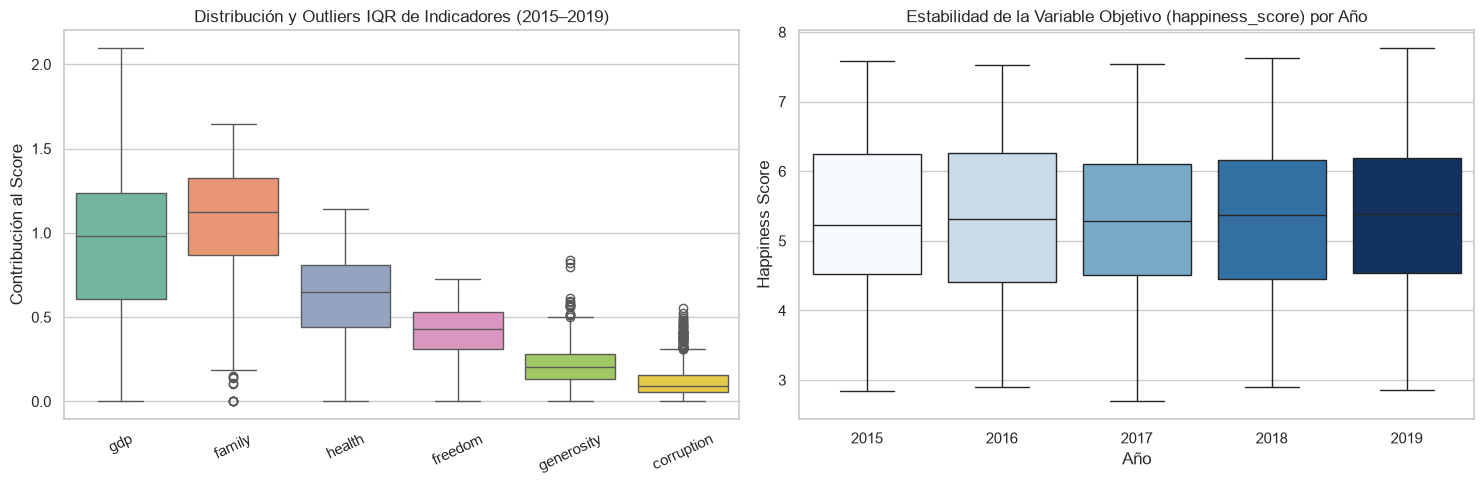

In [6]:
# 4. Visualizaciones de diagnóstico (distribuciones y outliers por variable y año)
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

sns.boxplot(
    data=preview_df[["gdp", "family", "health", "freedom", "generosity", "corruption"]],
    ax=axes[0],
    palette="Set2",
)
axes[0].set_title("Distribución y Outliers IQR de Indicadores (2015–2019)")
axes[0].set_ylabel("Contribución al Score")
axes[0].tick_params(axis="x", rotation=25)

sns.boxplot(data=preview_df, x="year", y="happiness_score", hue="year", legend=False, ax=axes[1], palette="Blues")
axes[1].set_title("Estabilidad de la Variable Objetivo (happiness_score) por Año")
axes[1].set_xlabel("Año")
axes[1].set_ylabel("Happiness Score")

plt.tight_layout()
plt.show()

### Observaciones Clave de Calidad de Datos y Propuesta de Esquema Unificado

#### Hallazgos del EDA
1. **Inconsistencia severa de nombres de columnas:**
   - `Country` (2015–2017) vs `Country or region` (2018–2019).
   - `Happiness Score` (2015–2016) vs `Happiness.Score` (2017) vs `Score` (2018–2019).
   - `Economy (GDP per Capita)` (2015–2016) vs `Economy..GDP.per.Capita.` (2017) vs `GDP per capita` (2018–2019).
   - `Family` (2015–2017) vs `Social support` (2018–2019).
   - `Health (Life Expectancy)` (2015–2016) vs `Health..Life.Expectancy.` (2017) vs `Healthy life expectancy` (2018–2019).
   - `Freedom` (2015–2017) vs `Freedom to make life choices` (2018–2019).
   - `Trust (Government Corruption)` (2015–2016) vs `Trust..Government.Corruption.` (2017) vs `Perceptions of corruption` (2018–2019).
2. **Diferencias estructurales entre años (columnas exclusivas de ciertos años):**
   - `Region` solo existe en 2015 y 2016.
   - `Standard Error` solo en 2015; `Lower/Upper Confidence Interval` solo en 2016; `Whisker.high/low` solo en 2017.
   - `Dystopia Residual` (`Dystopia.Residual`) existe solo en 2015–2017 y desaparece en 2018–2019.
3. **Valores faltantes y duplicados:**
   - **0 filas duplicadas** exactas y **0 duplicados** por `(country, year)`.
   - Únicamente **1 valor nulo** en los 782 registros: `United Arab Emirates` (2018) en `Perceptions of corruption`.
4. **Inconsistencias en nombres de países:**
   - Existen 6 pares de nombres que representan al mismo territorio con distinta grafía según el año (`Hong Kong S.A.R., China` vs `Hong Kong`, `Taiwan Province of China` vs `Taiwan`, `Trinidad & Tobago` vs `Trinidad and Tobago`, `Northern Cyprus` vs `North Cyprus`, `Macedonia` vs `North Macedonia`, `Somaliland region` vs `Somaliland Region`).
5. **Valores en cero y outliers:**
   - En la metodología del *World Happiness Report*, cada indicador mide la diferencia respecto al país mínimo de referencia (*Dystopia*), por lo que cada año el país con el valor más bajo recibe `0.000` (ej. Grecia en `generosity`, Somalia/CAR en `gdp`). No son datos faltantes.
   - Los outliers superiores en `corruption` corresponden a países nórdicos o de muy alta confianza institucional (Dinamarca, Finlandia, Singapur, Nueva Zelanda), y deben conservarse.

#### Propuesta de Esquema Analítico Unificado (`data/processed/happiness_unified.csv`)
| Columna Canónica | Tipo | Rol en el Pipeline |
| :--- | :--- | :--- |
| `country` | `string` | Llave de partición en Kafka y dimensión `dim_country` |
| `year` | `int64` | Metadato temporal de la observación histórica |
| `gdp` | `float64` | Feature predictiva (`gdp` en Event Contract) |
| `family` | `float64` | Feature predictiva (`family` en Event Contract) |
| `health` | `float64` | Feature predictiva (`health` en Event Contract) |
| `freedom` | `float64` | Feature predictiva (`freedom` en Event Contract) |
| `generosity` | `float64` | Feature predictiva (`generosity` en Event Contract) |
| `corruption` | `float64` | Feature predictiva (`corruption` en Event Contract) |
| `happiness_score` | `float64` | Variable objetivo (`actual_happiness_score` en Event Contract) |

## Paso 2 — Limpieza y Armonización de Datos

En la siguiente celda se ejecuta la transformación batch completa. Todas las decisiones de limpieza están documentadas directamente en los comentarios del código.

In [7]:
# Diccionario explícito de armonización de columnas por año -> esquema canónico alineado al Event Contract
SCHEMA_MAPPING: dict[int, dict[str, str]] = {
    2015: {
        "Country": "country",
        "Economy (GDP per Capita)": "gdp",
        "Family": "family",
        "Health (Life Expectancy)": "health",
        "Freedom": "freedom",
        "Generosity": "generosity",
        "Trust (Government Corruption)": "corruption",
        "Happiness Score": "happiness_score",
    },
    2016: {
        "Country": "country",
        "Economy (GDP per Capita)": "gdp",
        "Family": "family",
        "Health (Life Expectancy)": "health",
        "Freedom": "freedom",
        "Generosity": "generosity",
        "Trust (Government Corruption)": "corruption",
        "Happiness Score": "happiness_score",
    },
    2017: {
        "Country": "country",
        "Economy..GDP.per.Capita.": "gdp",
        "Family": "family",
        "Health..Life.Expectancy.": "health",
        "Freedom": "freedom",
        "Generosity": "generosity",
        "Trust..Government.Corruption.": "corruption",
        "Happiness.Score": "happiness_score",
    },
    2018: {
        "Country or region": "country",
        "GDP per capita": "gdp",
        "Social support": "family",
        "Healthy life expectancy": "health",
        "Freedom to make life choices": "freedom",
        "Generosity": "generosity",
        "Perceptions of corruption": "corruption",
        "Score": "happiness_score",
    },
    2019: {
        "Country or region": "country",
        "GDP per capita": "gdp",
        "Social support": "family",
        "Healthy life expectancy": "health",
        "Freedom to make life choices": "freedom",
        "Generosity": "generosity",
        "Perceptions of corruption": "corruption",
        "Score": "happiness_score",
    },
}

# JUSTIFICACIÓN DE EXCLUSIÓN DE COLUMNAS NO INCLUIDAS EN SCHEMA_MAPPING:
# 1. 'Happiness Rank' / 'Happiness.Rank' / 'Overall rank': se descarta porque es un derivado directo
#    del ordenamiento de la variable objetivo (happiness_score). Incluirla provocaría fuga de datos (target leakage).
# 2. 'Standard Error', 'Lower/Upper Confidence Interval', 'Whisker.high/low': representan bandas de error
#    estadístico calculadas sobre happiness_score (target leakage) y solo existen entre 2015 y 2017.
# 3. 'Dystopia Residual' / 'Dystopia.Residual': solo existe en 2015–2017 (ausente en 2018–2019) y completa
#    matemáticamente la suma exacta hasta happiness_score (incompatibilidad estructural + target leakage).
# 4. 'Region': solo está disponible en 2015–2016 (~40% de los años) y no forma parte del Event Contract de Kafka.

# JUSTIFICACIÓN DE NORMALIZACIÓN DE ENTIDADES DE PAÍS:
# Unificar variantes tipográficas históricas evita fragmentar el mismo país en múltiples registros dentro de la
# dimensión analítica 'dim_country' (PostgreSQL) y garantiza particionamiento consistente por llave 'country' en Kafka.
COUNTRY_CANONICAL_MAP: dict[str, str] = {
    "Hong Kong S.A.R., China": "Hong Kong",
    "Taiwan Province of China": "Taiwan",
    "Trinidad & Tobago": "Trinidad and Tobago",
    "Northern Cyprus": "North Cyprus",
    "Macedonia": "North Macedonia",
    "Somaliland region": "Somaliland Region",
}

UNIFIED_COLUMNS = [
    "country",
    "year",
    "gdp",
    "family",
    "health",
    "freedom",
    "generosity",
    "corruption",
    "happiness_score",
]
NUMERIC_COLUMNS = ["gdp", "family", "health", "freedom", "generosity", "corruption", "happiness_score"]

harmonized_frames = []
for year, col_map in SCHEMA_MAPPING.items():
    df_raw = raw_datasets[year]
    # Seleccionar y renombrar exclusivamente las columnas del esquema unificado
    df_clean = df_raw[list(col_map.keys())].rename(columns=col_map).copy()
    # Inyectar columna 'year' explícita porque los archivos originales no la contienen internamente
    df_clean["year"] = year
    harmonized_frames.append(df_clean)

df_unified = pd.concat(harmonized_frames, ignore_index=True)

# JUSTIFICACIÓN DE ESTANDARIZACIÓN DE TIPOS Y TEXTO:
# - Se eliminan espacios en los extremos de 'country' y se aplica el diccionario canónico.
# - Se fuerza 'year' a int64 y todas las métricas numéricas a float64 para asegurar compatibilidad con PostgreSQL,
#   el Pipeline de scikit-learn y la serialización JSON del productor de Kafka.
df_unified["country"] = (
    df_unified["country"]
    .astype(str)
    .str.strip()
    .replace(COUNTRY_CANONICAL_MAP)
)
df_unified["year"] = pd.to_numeric(df_unified["year"], errors="raise").astype("int64")
for col in NUMERIC_COLUMNS:
    df_unified[col] = pd.to_numeric(df_unified[col], errors="raise").astype("float64")

# JUSTIFICACIÓN DEL MANEJO DE VALORES FALTANTES:
# Solo existe 1 registro con valor nulo en los 5 años: United Arab Emirates (2018) en 'corruption'.
# - Decisión: imputar con la mediana histórica del propio país (UAE: ~0.3400 en 2015-2019), con respaldo a mediana
#   global si apareciera un país nuevo sin historial.
# - Por qué NO eliminar la fila: perderíamos un registro válido en sus demás indicadores socioeconómicos.
# - Por qué NO usar mediana global (~0.091): subestimaría severamente la confianza institucional histórica de UAE (~0.34).
# - Beneficio para streaming: eliminar nulos en el dataset procesado evita emitir 'NaN'/'null' inválidos en JSON hacia Kafka.
country_medians = df_unified.groupby("country")["corruption"].transform("median")
df_unified["corruption"] = df_unified["corruption"].fillna(country_medians).fillna(df_unified["corruption"].median())

# JUSTIFICACIÓN DE RETENCIÓN DE CEROS Y OUTLIERS:
# - Los ceros (ej. Grecia en generosity, Somalia/CAR en gdp) son valores reales del ancla Dystopia de cada año.
# - Los valores altos de 'corruption' (>0.309) representan países con muy baja percepción de corrupción (nórdicos/Singapur).
#   Eliminarlos sesgaría el modelo fuera del rango superior real; por ello se conservan intactos.

# Ordenamiento determinista de columnas y filas para reproducibilidad
df_unified = df_unified[UNIFIED_COLUMNS].sort_values(by=["year", "country"]).reset_index(drop=True)

print("Vista previa del dataset armonizado:")
display(df_unified.head(10))

Vista previa del dataset armonizado:


,country,year,gdp,family,health,freedom,generosity,corruption,happiness_score
0,Afghanistan,2015,0.31982,0.30285,0.30335,0.23414,0.36510,0.09719,3.575
1,Albania,2015,0.87867,0.80434,0.81325,0.35733,0.14272,0.06413,4.959
2,Algeria,2015,0.93929,1.07772,0.61766,0.28579,0.07822,0.17383,5.605
3,Angola,2015,0.75778,0.86040,0.16683,0.10384,0.12344,0.07122,4.033
4,Argentina,2015,1.05351,1.24823,0.78723,0.44974,0.11451,0.08484,6.574
5,Armenia,2015,0.76821,0.77711,0.72990,0.19847,0.07855,0.03900,4.350
6,Australia,2015,1.33358,1.30923,0.93156,0.65124,0.43562,0.35637,7.284
7,Austria,2015,1.33723,1.29704,0.89042,0.62433,0.33088,0.18676,7.200
8,Azerbaijan,2015,1.02389,0.93793,0.64045,0.37030,0.07799,0.16065,5.212
9,Bahrain,2015,1.32376,1.21624,0.74716,0.45492,0.17362,0.30600,5.960


In [8]:
# Validación estricta post-limpieza (Data Quality Gate antes de exportar)
assert list(df_unified.columns) == UNIFIED_COLUMNS, "El orden o nombre de columnas no coincide con el esquema."
assert df_unified.isna().sum().sum() == 0, "Aún existen valores nulos en el dataset unificado."
assert df_unified.duplicated(subset=["country", "year"]).sum() == 0, "Existen duplicados (country, year)."
assert (df_unified[NUMERIC_COLUMNS] >= 0).all().all(), "Se detectaron valores numéricos negativos."
assert df_unified["country"].str.len().gt(0).all(), "Existen países vacíos."

output_path = PROCESSED_DIR / "happiness_unified.csv"
df_unified.to_csv(output_path, index=False)

print(f"Dataset armonizado exportado exitosamente a: {output_path}")
print(f"Dimensiones finales: {df_unified.shape[0]} filas x {df_unified.shape[1]} columnas")
print(f"Países únicos armonizados: {df_unified['country'].nunique()}")
print(f"Rango de años: {df_unified['year'].min()} - {df_unified['year'].max()}")

Dataset armonizado exportado exitosamente a: C:\Users\jagui\Desktop\UNIVERSIDAD\ETL\workshop_3\data\processed\happiness_unified.csv
Dimensiones finales: 782 filas x 9 columnas
Países únicos armonizados: 164
Rango de años: 2015 - 2019
